# BSW ToDos:

1.   Run regressions in R
2.   Run C&S's DiD in R
3.   Store results to drive along with Event Study Images
4.   Provide Outline for Draft


# ToDos

1. take the average of the month instead of the actual value on that day -- completed
2. do regression on the unemployment data too -- completed
3.** update the law passed dataset** and include the descriptions of the laws as well  
4. make one final csv of the whole data with all the consolidated data and date it -- completed
5. make one monthly average data and one daily data (with unemployment data for every single day in the month)
6. go through all the links he sent me, specifically "Getting Started with the did Package" and do the did code in R
7. read the link on linkedin
8. do the event study in a monthly level

2. If i have time look into the regression coefficient - store results run again?


May consolidate data to weeks or months?
See if there is any sign of flat pretrends

## Optional

1. Hide all the date and state outputs on the linear regression
2. Check if other states have passed laws related to wage/salary disclosure in job postings in the meantime, update the lawpassed date. Add "source of law date" in original spreadsheet.
3. Are there any variables we can collect that vary by state and change nearly every day?   Ideas:

*   Google search for jobs? Could exist daily.
*   American Community Survey 1-year state estimates:https://data.census.gov/all?d=ACS%201-Year%20Estimates%20Detailed%20Tables
https://www.census.gov/data/datasets/time-series/demo/popest/2020s-state-detail.html

4. calloway and san'tanna!









In [ ]:
#getting quarterly data for employment by industry to use because of our RR
#takes a while to run so only run once and save it to your machine and upload into the data section
"""
import pandas as pd
import os
import glob

def append_xlsx_to_csv(input_folder, output_csv):
    all_dataframes = []
    for filename in glob.glob(os.path.join(input_folder, "*.xlsx")):
        try:
            df = pd.read_excel(filename)
            all_dataframes.append(df)
        except Exception as e:
            print(f"Error reading file {filename}: {e}")
    if all_dataframes:
      combined_df = pd.concat(all_dataframes, ignore_index=True)
      combined_df.to_csv(output_csv, index=False)
      print(f"Successfully combined data into {output_csv}")
    else:
        print("No .xlsx files found in the specified directory")

input_folder = "/content/sample_data/RR/"  # Replace path to folder
output_csv = "combined_data.csv"
append_xlsx_to_csv(input_folder, output_csv)
from google.colab import files
files.download('combined_data.csv')

"""

'\nimport pandas as pd\nimport os\nimport glob\n\ndef append_xlsx_to_csv(input_folder, output_csv):\n    all_dataframes = []\n    for filename in glob.glob(os.path.join(input_folder, "*.xlsx")):\n        try:\n            df = pd.read_excel(filename)\n            all_dataframes.append(df)\n        except Exception as e:\n            print(f"Error reading file {filename}: {e}")\n    if all_dataframes:\n      combined_df = pd.concat(all_dataframes, ignore_index=True)\n      combined_df.to_csv(output_csv, index=False)\n      print(f"Successfully combined data into {output_csv}")\n    else:\n        print("No .xlsx files found in the specified directory")\n\ninput_folder = "/content/sample_data/RR/"  # Replace path to folder\noutput_csv = "combined_data.csv"\nappend_xlsx_to_csv(input_folder, output_csv)\nfrom google.colab import files\nfiles.download(\'combined_data.csv\')\n\n'

# Dependencies and Functions

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression

In [ ]:
df = pd.read_csv('combined_data.csv')
df = df.drop(columns=['Area\nCode', 'St', 'Cnty', 'Own', 'NAICS', 'Area', 'Area Type', 'Status Code', 'Establishment Count'])

df.head()


<ipython-input-3-d8d1b4e67ad5>:1: DtypeWarning: Columns (0,1) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('combined_data.csv')


,Year,Qtr,St Name,Ownership,Industry,January Employment,February Employment,March Employment,Total Quarterly Wages,Average Weekly Wage,...,Total Wage Location Quotient Relative to U.S.,July Employment,August Employment,September Employment,October Employment,November Employment,December Employment,April Employment,May Employment,June Employment
0,2022,1,NaN,Total Covered,"10 Total, all industries",145546514.0,147135587.0,147775977.0,2623077175426,1374,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2022,1,NaN,Federal Government,"10 Total, all industries",2859961.0,2856442.0,2849621.0,60777488766,1637,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2022,1,NaN,State Government,"10 Total, all industries",4460342.0,4534065.0,4538818.0,78932158185,1346,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2022,1,NaN,Local Government,"10 Total, all industries",13939765.0,14049196.0,14100249.0,203192276910,1114,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2022,1,NaN,Private,"10 Total, all industries",124286446.0,125695884.0,126287289.0,2280175251565,1398,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:

df = pd.read_csv('combined_data.csv')

# Filter the 'Area Type' column to only include 'State'
df_filtered = df[df['Area Type'] == 'State']
df = df_filtered.drop(columns=['Area','Area\nCode', 'Own','St', 'Area Type','Cnty', 'NAICS','Status Code', 'Establishment Count', 'Total Wage Location Quotient Relative to U.S.','Employment Location Quotient Relative to U.S.'])

# Rename columns containing " Employment"
for col in df.columns:
    if " Employment" in col:
        new_col = col.replace(" Employment", "")
        df = df.rename(columns={col: new_col})


#  go from wide Monthly data to long monthly data, for example if the January column has a number and is not NaN, make a column for that January of that Year from the year column that has that exact month value but keep Ownership, St Name, Industry columns

import pandas as pd

def wide_to_long_monthly(df):
    # Identify columns representing months
    month_cols = [col for col in df.columns if col.lower() in ['january', 'february', 'march', 'april', 'may', 'june', 'july', 'august', 'september', 'october', 'november', 'december']]

    # Create an empty list to store the transformed data
    long_data = []

    # Iterate over each row in the DataFrame
    for index, row in df.iterrows():
        for month_col in month_cols:
            if not pd.isna(row[month_col]):
                # Extract relevant information
                year = row['Year']
                month = month_col.capitalize()  # Capitalize month for consistency
                ownership = row['Ownership']
                st_name = row['St Name']
                industry = row['Industry']
                average_weekly_wage = row['Average Weekly Wage']
                total_1uarterly_wages= row['Total Quarterly Wages']
                month_value = row[month_col]

                # Append the information to the list
                long_data.append({
                    'Year': year,
                    'Month': month,
                    'Ownership': ownership,
                    'St Name': st_name,
                    'Industry': industry,
                    'Average Weekly Wage': average_weekly_wage,
                    'Total Quarterly Wages': total_1uarterly_wages,
                    'Employment': month_value
                })

    # Create a new DataFrame from the transformed data
    df_melted = pd.DataFrame(long_data)

    return df_melted

# Assuming 'df' is your wide DataFrame
df_melted = wide_to_long_monthly(df)
print(df_melted.head())

<ipython-input-4-066a1e506538>:1: DtypeWarning: Columns (0,1) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('combined_data.csv')


   Year     Month           Ownership  St Name                  Industry  \
0  2022   January       Total Covered  Alabama  10 Total, all industries   
1  2022  February       Total Covered  Alabama  10 Total, all industries   
2  2022     March       Total Covered  Alabama  10 Total, all industries   
3  2022   January  Federal Government  Alabama  10 Total, all industries   
4  2022  February  Federal Government  Alabama  10 Total, all industries   

   Average Weekly Wage  Total Quarterly Wages  Employment  
0                 1069            27713067504   1979365.0  
1                 1069            27713067504   2002560.0  
2                 1069            27713067504   2002768.0  
3                 1643             1175019330     55185.0  
4                 1643             1175019330     54994.0  


In [ ]:
df_melted.head()

,Year,Month,Ownership,St Name,Industry,Average Weekly Wage,Total Quarterly Wages,Employment
0,2022,January,Total Covered,Alabama,"10 Total, all industries",1069,27713067504,1979365.0
1,2022,February,Total Covered,Alabama,"10 Total, all industries",1069,27713067504,2002560.0
2,2022,March,Total Covered,Alabama,"10 Total, all industries",1069,27713067504,2002768.0
3,2022,January,Federal Government,Alabama,"10 Total, all industries",1643,1175019330,55185.0
4,2022,February,Federal Government,Alabama,"10 Total, all industries",1643,1175019330,54994.0


In [ ]:
df_melted['Month'] = df_melted['Month'].astype(str)
df_melted['Year'] = df_melted['Year'].astype(int)

# Convert month names to numbers if they are not already numbers
month_mapping = {
    'January': '01', 'February': '02', 'March': '03', 'April': '04',
    'May': '05', 'June': '06', 'July': '07', 'August': '08',
    'September': '09', 'October': '10', 'November': '11', 'December': '12'
}
df_melted['Month'] = df_melted['Month'].map(month_mapping).fillna(df_melted['Month'])

# Combine 'Year' and 'Month' to create the date column
df_melted['Date'] = pd.to_datetime(df_melted['Year'].astype(str) + '-' + df_melted['Month'], format='%Y-%m', errors='coerce')
df_melted.head()


,Year,Month,Ownership,St Name,Industry,Average Weekly Wage,Total Quarterly Wages,Employment,Date
0,2022,01,Total Covered,Alabama,"10 Total, all industries",1069,27713067504,1979365.0,2022-01-01
1,2022,02,Total Covered,Alabama,"10 Total, all industries",1069,27713067504,2002560.0,2022-02-01
2,2022,03,Total Covered,Alabama,"10 Total, all industries",1069,27713067504,2002768.0,2022-03-01
3,2022,01,Federal Government,Alabama,"10 Total, all industries",1643,1175019330,55185.0,2022-01-01
4,2022,02,Federal Government,Alabama,"10 Total, all industries",1643,1175019330,54994.0,2022-02-01







**Graphing**





In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_employment_by_industry(df_melted, state):
    # Filter data for the specified state
    state_data = df_melted[df_melted['St Name'] == state]

    # Create the plot
    plt.figure(figsize=(12, 6))
    sns.lineplot(x='Year', y='Employment', hue='Industry', data=state_data, marker='o')
    plt.title(f'Employment by Industry in {state} (Quarterly)')
    plt.xlabel('Year')
    plt.ylabel('Employment')
    plt.xticks(rotation=45)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left') # Move legend outside plot
    plt.tight_layout() # Adjust layout to prevent labels from overlapping
    plt.show()

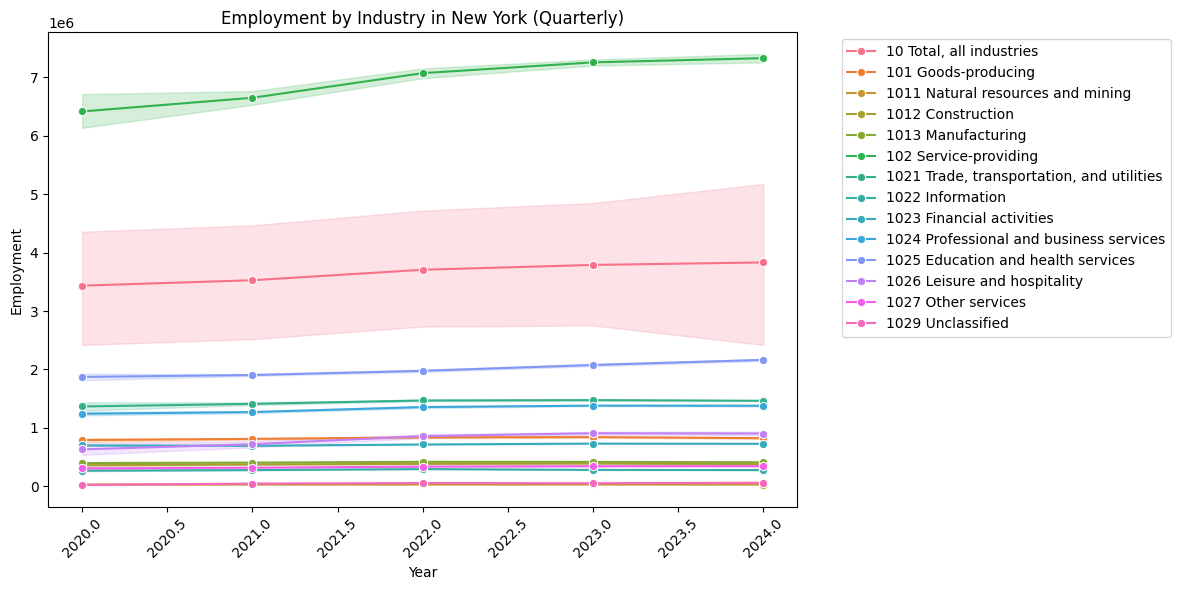

In [ ]:
plot_employment_by_industry(df_melted, "New York")

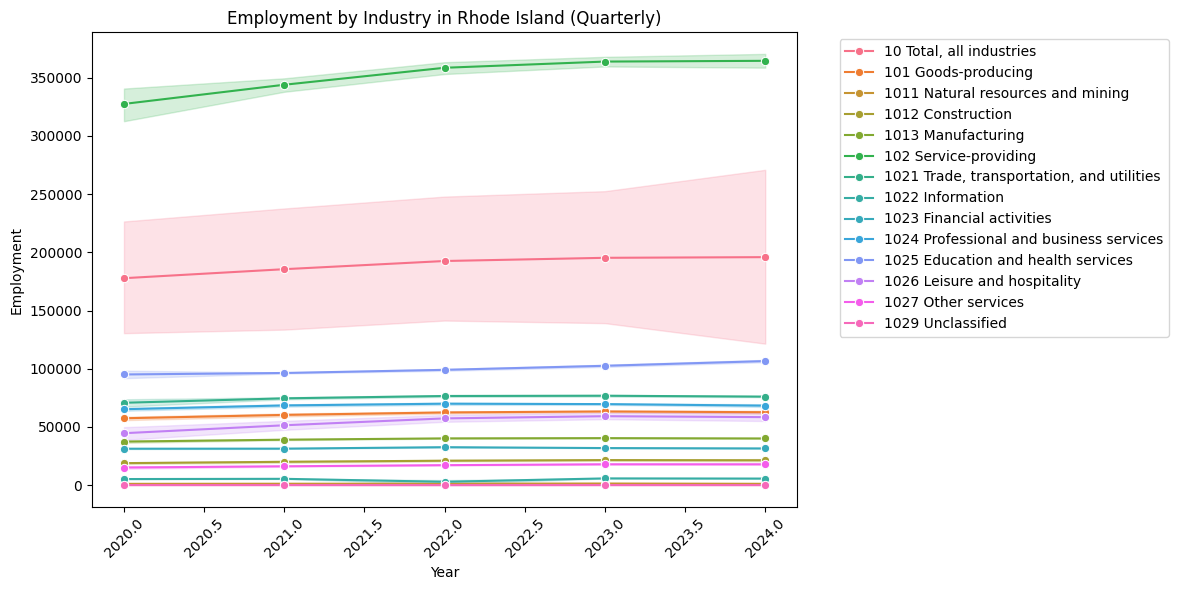

In [ ]:
plot_employment_by_industry(df_melted, "Rhode Island")

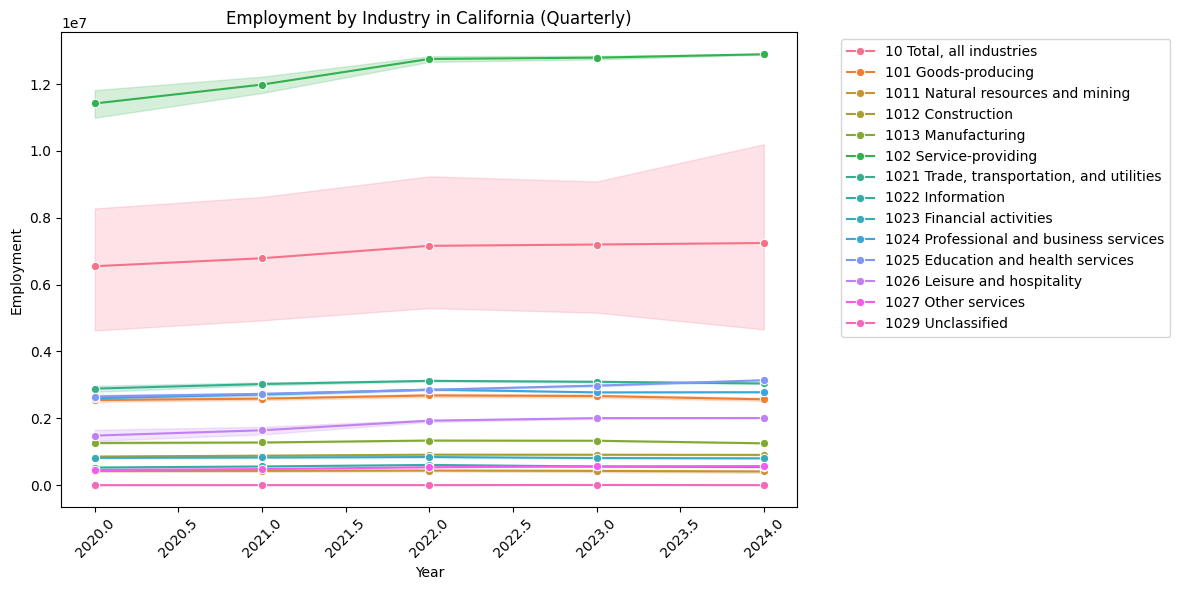

In [ ]:
plot_employment_by_industry(df_melted, "California")

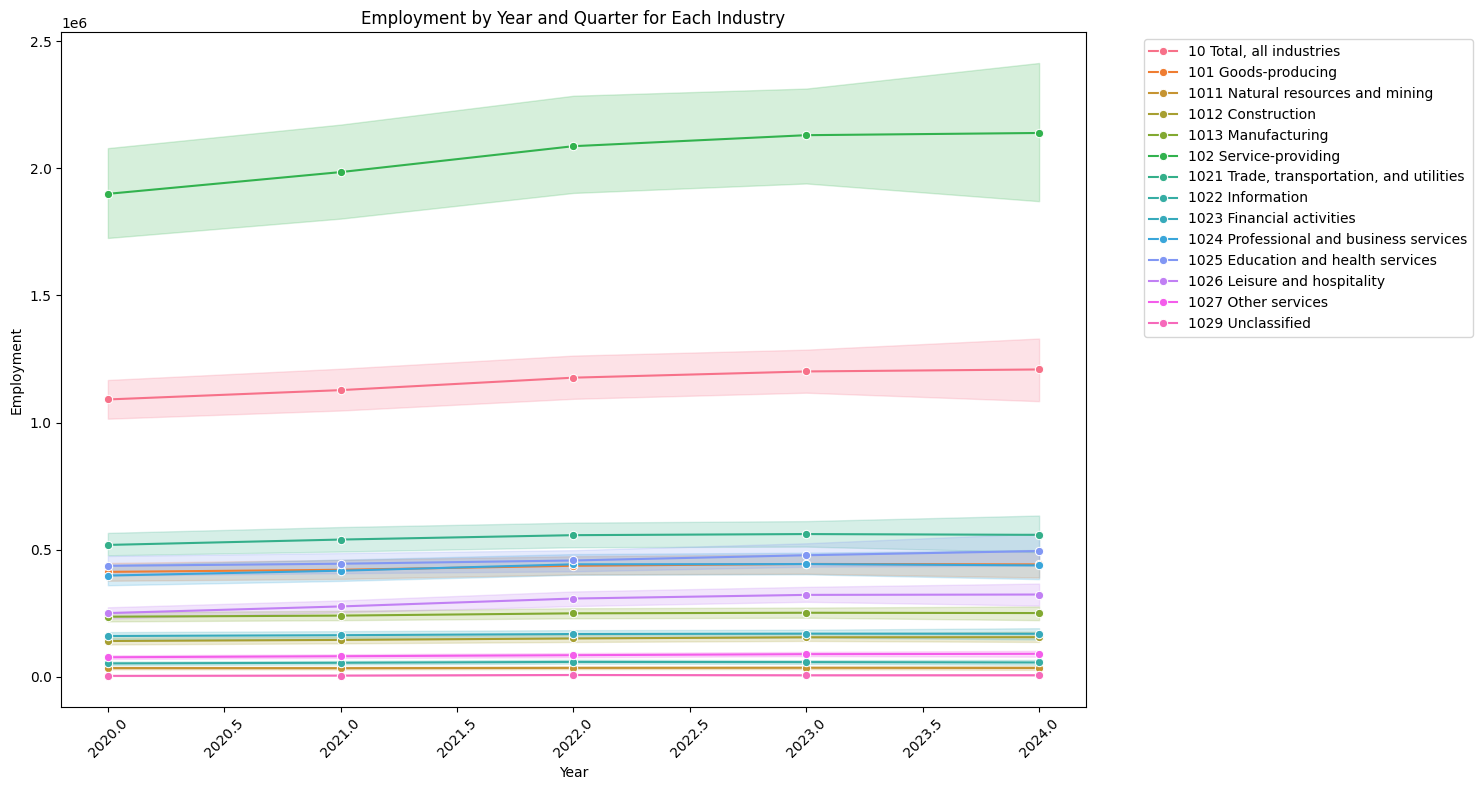

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns



plt.figure(figsize=(15, 8))  # Adjust figure size as needed
sns.lineplot(x='Year', y='Employment', hue='Industry', data=df_melted, marker='o')
plt.xlabel("Year")
plt.ylabel("Employment")
plt.title("Employment by Year and Quarter for Each Industry")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left') # Move legend outside plot
plt.xticks(rotation=45) # Rotate x-axis labels for better readability
plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.show()

In [ ]:
null_counts = df_melted.groupby('Month')['Employment'].apply(lambda x: x.isnull().sum() + (x == '').sum())
null_counts

,Employment
Month,
01,0
02,0
03,0
04,0
05,0
06,0
07,0
08,0
09,0


In [ ]:
# Graph Preliminary DID function with data
def detail_graph(df, yVar, titleHere):
    df_left = df[df["date_passed"].notnull()]
    x = df_left[df_left["date_passed"].notnull()]["from_baseline"]
    x = df_left["from_baseline"]
    y = df_left[yVar]

    plt.figure(figsize=(10,5))
    plt.scatter(x, y)
    df_left = df.copy()
    df_left = df_left[df_left["from_baseline"] <0]
    #x = df_left["date_passed"].notnull()["from_baseline"]
    x_left = df_left["from_baseline"]
    y_left = df_left[yVar]
    plt.axvline(x = 0, color = 'r', label = 'axvline - full height')



    #first linear regression


    x = df_left[["from_baseline"]]
    #x = df_left["date_passed"].notnull()["from_baseline"]
    y = df_left[yVar]

    lr = LinearRegression()
    lr.fit(x, y)
    plt.plot(x, lr.predict(x), color = "green")



    # second linear reg

    df_right = df[df["from_baseline"] > 0]
    #x = df_left["date_passed"].notnull()["from_baseline"]
    x = df_right[["from_baseline"]]
    y = df_right[yVar]

    lr = LinearRegression()
    lr.fit(x, y)
    plt.plot(x, lr.predict(x), color = "purple")




    plt.xlabel('date baseline: as Independent variable')
    plt.ylabel('% baseline: as Dependent variable')
    plt.title(titleHere);


# Data Management and Cleaning

In [ ]:
#Load data and convert into a loadable format

dfJobs = pd.read_csv('state_job_postings_us_072924.csv')
dfJobs['date'] = pd.to_datetime(dfJobs['date'])

dfLaws = pd.read_csv('LawPassed_072424.csv')
dfLaws['state'] = dfLaws['state'].str.lower()
dfLaws['date'] = pd.to_datetime(dfLaws['Date'], format='mixed')

#joining the two dfs and creating our own from_baseline column
joinedDF = pd.merge(dfLaws, dfJobs, on='state', how = 'right')
joinedDF["from_baseline"] = (joinedDF["date_y"] - joinedDF["date_x"]).dt.days

# adding a new column on the joinedDF data frame called passed_flag that is 1 if date_y column is greater than or equal to date_x 0 otherwise
joinedDF["is_date_passed"] = np.where(joinedDF["date_y"] >= joinedDF["date_x"], 1, 0)


#renaming and dropping unnecesary columns
joinedDF.rename(columns={"date_x": "date_passed"}, inplace=True)
joinedDF.rename(columns={"date_y": "date"}, inplace=True)
joinedDF.drop("Date", axis=1, inplace=True)
#joinedDF['year_month'] = joinedDF['date'].dt.to_period('M')
joinedDF.head()

,state,date_passed,date,indeed_job_postings_index,from_baseline,is_date_passed
0,ak,NaT,2020-02-01,100.00,NaN,0
1,ak,NaT,2020-02-02,99.64,NaN,0
2,ak,NaT,2020-02-03,99.46,NaN,0
3,ak,NaT,2020-02-04,99.39,NaN,0
4,ak,NaT,2020-02-05,99.40,NaN,0


In [ ]:
# Group by month and state, calculate mean for indeed_job_postings_index,
joinedDF_monthly = joinedDF.groupby(['state', joinedDF['date'].dt.to_period('M')]).agg({'indeed_job_postings_index': 'mean', 'is_date_passed': 'max', 'from_baseline': 'first','date_passed': 'first'}).reset_index()

# Rename the date column
joinedDF_monthly.rename(columns={'date': 'year_month'}, inplace=True)

# Convert year_month back to datetime
joinedDF_monthly['date'] = joinedDF_monthly['year_month'].dt.to_timestamp()

joinedDF_monthly.head()
joinedDF_monthly

,state,year_month,indeed_job_postings_index,is_date_passed,from_baseline,date_passed,date
0,ak,2020-02,100.198966,0,NaN,NaT,2020-02-01
1,ak,2020-03,94.478387,0,NaN,NaT,2020-03-01
2,ak,2020-04,70.970000,0,NaN,NaT,2020-04-01
3,ak,2020-05,66.380323,0,NaN,NaT,2020-05-01
4,ak,2020-06,73.885667,0,NaN,NaT,2020-06-01
...,...,...,...,...,...,...,...
2749,wy,2024-03,136.371290,0,NaN,NaT,2024-03-01
2750,wy,2024-04,137.503667,0,NaN,NaT,2024-04-01
2751,wy,2024-05,133.743548,0,NaN,NaT,2024-05-01
2752,wy,2024-06,130.876667,0,NaN,NaT,2024-06-01


In [ ]:

joinedDF_monthly = joinedDF.groupby(['state', joinedDF['date'].dt.to_period('M')]).agg(
    {'indeed_job_postings_index': 'mean',
     'is_date_passed': 'max',
     'date_passed': 'first',
     'from_baseline': lambda x: 0 if (x == 0).any() else x.iloc[0]
    }).reset_index()

# Rename the date column
joinedDF_monthly.rename(columns={'date': 'year_month'}, inplace=True)

# Convert year_month back to datetime
joinedDF_monthly['date'] = joinedDF_monthly['year_month'].dt.to_timestamp()

joinedDF_monthly.head()


,state,year_month,indeed_job_postings_index,is_date_passed,date_passed,from_baseline,date
0,ak,2020-02,100.198966,0,NaT,NaN,2020-02-01
1,ak,2020-03,94.478387,0,NaT,NaN,2020-03-01
2,ak,2020-04,70.970000,0,NaT,NaN,2020-04-01
3,ak,2020-05,66.380323,0,NaT,NaN,2020-05-01
4,ak,2020-06,73.885667,0,NaT,NaN,2020-06-01


In [ ]:
# (FRED API no longer used; the next cell reads the local fredgraph-*.csv files)


In [ ]:
UNData1 = pd.read_csv('fredgraph-2-070124.csv')
UNData2 = pd.read_csv('fredgraph-3-070124.csv')
UNData3 = pd.read_csv('fredgraph-4-070124.csv')
UNData4 = pd.read_csv('fredgraph-5-070124.csv')
UNData5 = pd.read_csv('fredgraph-6-070124.csv')

# If you want to join based on 'DATE' and keep only the common dates:
all_UN_data_joined = pd.merge(UNData1, UNData2, on='DATE') \
    .merge(UNData3, on='DATE') \
    .merge(UNData4, on='DATE') \
    .merge(UNData5, on='DATE')
all_UN_data_joined.head()


In [ ]:
#px.line(all_UN_data_joined)

In [ ]:
# Old code -- now we get the data through an API from FRED
#this section gets the unemployemnt data, combines it and cleans it up
"""
UNData1 = pd.read_csv('fredgraph-2-070124.csv')
UNData2 = pd.read_csv('fredgraph-3-070124.csv')
UNData3 = pd.read_csv('fredgraph-4-070124.csv')
UNData4 = pd.read_csv('fredgraph-5-070124.csv')
UNData5 = pd.read_csv('fredgraph-6-070124.csv')

# If you want to join based on 'DATE' and keep only the common dates:
all_UN_data_joined = pd.merge(UNData1, UNData2, on='DATE') \
    .merge(UNData3, on='DATE') \
    .merge(UNData4, on='DATE') \
    .merge(UNData5, on='DATE')
all_UN_data_joined.head()
"""

#cleaning up the headers
# Replace "URN" in column names and convert to lowercase and get a clean state name
all_UN_data_joined.columns = all_UN_data_joined.columns.str.replace('URN', '').str.lower()
all_UN_data_joined['date'] = pd.to_datetime(all_UN_data_joined['date'])
#all_UN_data_joined['month_year'] = all_UN_data_joined['date'].dt.to_period('M')
all_UN_data_joined.head()



# Melt the DataFrame to combine all unemployment rate columns into one
all_UN_data_melted = pd.melt(all_UN_data_joined, id_vars=['date'], var_name='state', value_name='unemployment_rate')
#all_UN_data_melted['state'] = all_UN_data_melted['state'].str.capitalize()


joinedDF_monthly['state'] = joinedDF_monthly['state'].str.upper()
all_UN_data_melted['state'] = all_UN_data_melted['state'].str.upper()


all_UN_data_melted['date'] = pd.to_datetime(all_UN_data_melted['date'])
# Extract the state abbreviations from the 'state' column
all_UN_data_melted['state'] = all_UN_data_melted['state'].str.extract(r'(\w{2})$')

# Display the resulting DataFrame
all_UN_data_melted.head()


#join
joinedDF_with_unemployment = pd.merge(joinedDF_monthly, all_UN_data_melted, on=['state', 'date'], how='left')
joinedDF_with_unemployment['unemployment_rate'] = joinedDF_with_unemployment['unemployment_rate'].astype(float)

# Display the resulting DataFrame
joinedDF_with_unemployment.head()


,state,year_month,indeed_job_postings_index,is_date_passed,date_passed,from_baseline,date,unemployment_rate
0,AK,2020-02,100.198966,0,NaT,NaN,2020-02-01,5.7
1,AK,2020-03,94.478387,0,NaT,NaN,2020-03-01,7.0
2,AK,2020-04,70.970000,0,NaT,NaN,2020-04-01,11.8
3,AK,2020-05,66.380323,0,NaT,NaN,2020-05-01,12.1
4,AK,2020-06,73.885667,0,NaT,NaN,2020-06-01,11.2


In [ ]:

# Drop rows where 'unemployment_rate' is empty
joinedDF_with_unemployment = joinedDF_with_unemployment.dropna(subset=['unemployment_rate'])
joinedDF_with_unemployment.head()

,state,year_month,indeed_job_postings_index,is_date_passed,date_passed,from_baseline,date,unemployment_rate
0,AK,2020-02,100.198966,0,NaT,NaN,2020-02-01,5.7
1,AK,2020-03,94.478387,0,NaT,NaN,2020-03-01,7.0
2,AK,2020-04,70.970000,0,NaT,NaN,2020-04-01,11.8
3,AK,2020-05,66.380323,0,NaT,NaN,2020-05-01,12.1
4,AK,2020-06,73.885667,0,NaT,NaN,2020-06-01,11.2


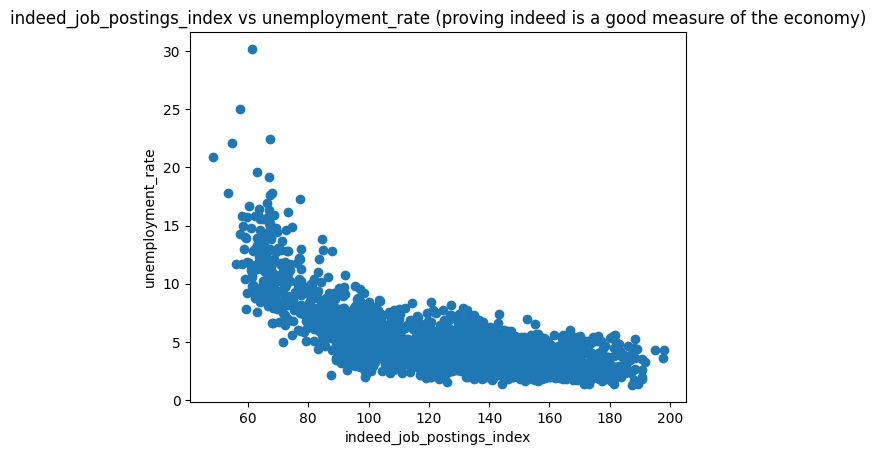

In [ ]:
x = joinedDF_with_unemployment[['indeed_job_postings_index']]
x1 = joinedDF_with_unemployment[['unemployment_rate']]

plt.scatter(x,x1)
plt.xlabel('indeed_job_postings_index')
plt.ylabel('unemployment_rate')
plt.title('indeed_job_postings_index vs unemployment_rate (proving indeed is a good measure of the economy)')
plt.show()


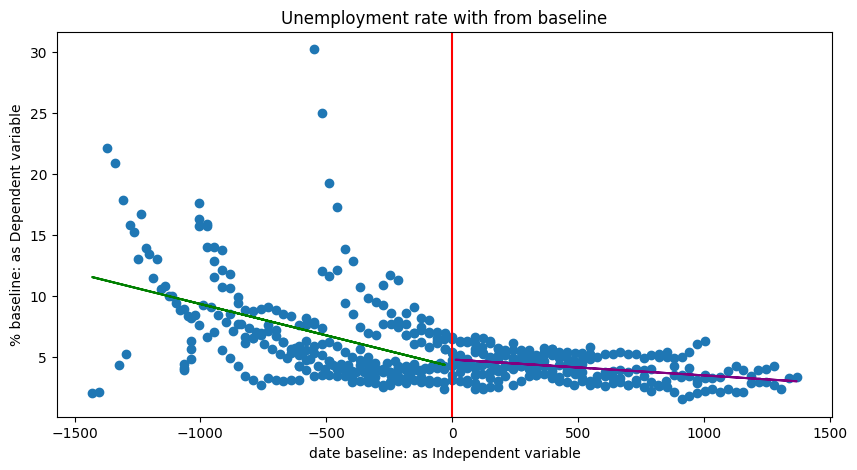

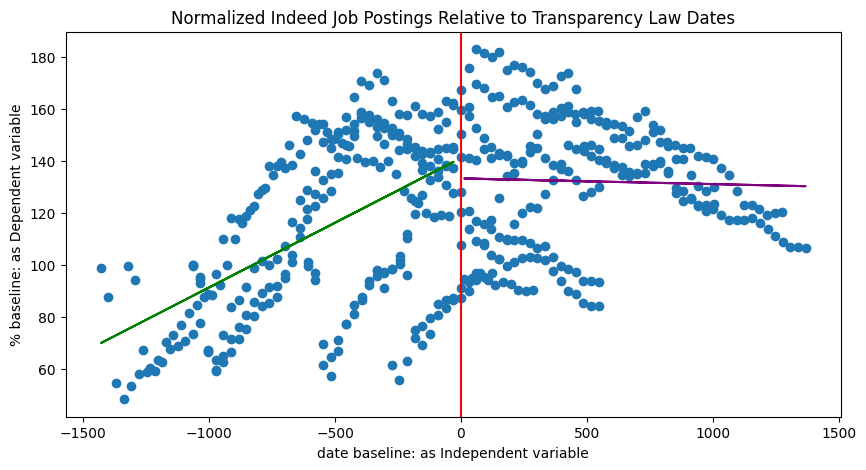

In [ ]:
# prompt: graph unemployment_rate with from baseline as x-axis

detail_graph(joinedDF_with_unemployment, "unemployment_rate", "Unemployment rate with from baseline")

detail_graph(joinedDF_with_unemployment, "indeed_job_postings_index", "Normalized Indeed Job Postings Relative to Transparency Law Dates")
#Y: Indeed Job Postings, Normalized to 100
#X: Date Transparency Law Passed, Normalized to 0
#Same Color line before and After, 95% SE bars also?

### **Getting Covid Data and storing it to covid_df**

In [ ]:
"""
all_dfs = []
for state in joinedDF_with_unemployment['state'].unique():
  # Do something with each state
  link = "https://storage.googleapis.com/covid19-open-data/v3/location/US_" + state + ".csv"
  df = pd.read_csv(link)
  all_dfs.append(df)


covid_df_orig = pd.concat(all_dfs)
covid_df_orig['location_key'] = covid_df_orig['location_key'].str.replace('US_', '')
covid_df_orig['location_key'] = covid_df_orig['location_key'].str.lower()
covid_df_orig['date'] = pd.to_datetime(covid_df_orig['date'])


#checking if it has the covid death columns
'cumulative_deceased' in df.columns
covid_df_orig.head()

# Group by 'location_key' and 'week' and sum 'cumulative_deceased' for every Tuesday
covid_df_weekly = covid_df_orig[covid_df_orig['date'].dt.weekday == 1].groupby(['location_key', pd.Grouper(key='date', freq='W-TUE')])['cumulative_deceased'].sum().reset_index()


# Rename the 'date' column to 'week_ending'
covid_df_weekly.rename(columns={'date': 'week_ending'}, inplace=True)

# Convert 'week_ending' to datetime objects
covid_df_weekly['week_ending'] = pd.to_datetime(covid_df_weekly['week_ending'])

# Sort the DataFrame by 'week_ending' in ascending order
covid_df_weekly.sort_values('week_ending', inplace=True)

# Display the resulting DataFrame
covid_df_weekly.head()


"""

'\nall_dfs = []\nfor state in joinedDF_with_unemployment[\'state\'].unique():\n  # Do something with each state\n  link = "https://storage.googleapis.com/covid19-open-data/v3/location/US_" + state + ".csv"\n  df = pd.read_csv(link)\n  all_dfs.append(df)\n\n\ncovid_df_orig = pd.concat(all_dfs)\ncovid_df_orig[\'location_key\'] = covid_df_orig[\'location_key\'].str.replace(\'US_\', \'\')\ncovid_df_orig[\'location_key\'] = covid_df_orig[\'location_key\'].str.lower()\ncovid_df_orig[\'date\'] = pd.to_datetime(covid_df_orig[\'date\'])\n\n\n#checking if it has the covid death columns\n\'cumulative_deceased\' in df.columns\ncovid_df_orig.head()\n\n# Group by \'location_key\' and \'week\' and sum \'cumulative_deceased\' for every Tuesday\ncovid_df_weekly = covid_df_orig[covid_df_orig[\'date\'].dt.weekday == 1].groupby([\'location_key\', pd.Grouper(key=\'date\', freq=\'W-TUE\')])[\'cumulative_deceased\'].sum().reset_index()\n\n\n# Rename the \'date\' column to \'week_ending\'\ncovid_df_weekly.ren

In [ ]:
with open('covid_concatinated_crude.csv', 'r') as infile, open('covid_concatinated_crude_clean.csv', 'w') as outfile:
    for line in infile:
        if "Data Table for Weekly" not in line and "Date generated" not in line:
            outfile.write(line)

covid_df_weekly_crude = pd.read_csv('covid_concatinated_crude_clean.csv')
covid_df_weekly_crude.drop_duplicates(subset=['Geography', 'Date', 'Weekly Deaths', 'Total Deaths Per 100000 (crude)', 'Death Data As Of'], keep='first', inplace=True)



covid_df_weekly_crude['Weekly Deaths'] = covid_df_weekly_crude['Weekly Deaths'].replace(['Counts 1-9'], 5)
covid_df_weekly_crude['Weekly Deaths'] = covid_df_weekly_crude['Weekly Deaths'].replace(['Counts <20'], 10)


covid_df_weekly_crude['Total Deaths Per 100000 (crude)'] = covid_df_weekly_crude['Total Deaths Per 100000 (crude)'].replace(['Counts 1-9'], 0)
covid_df_weekly_crude['Total Deaths Per 100000 (crude)'] = covid_df_weekly_crude['Total Deaths Per 100000 (crude)'].replace(['Counts <20'], 0)










with open('covid_concatinated_age_adjusted.csv', 'r') as infile, open('covid_concatinated_age_clean.csv', 'w') as outfile:
    for line in infile:
        if "Data Table for Weekly" not in line and "Date generated" not in line:
            outfile.write(line)

covid_df_weekly_age = pd.read_csv('covid_concatinated_age_clean.csv')
covid_df_weekly_age.drop_duplicates(subset=['Geography', 'Date', 'Weekly Deaths', 'Total Deaths Per 100000 (age-adjusted)', 'Death Data As Of'], keep='first', inplace=True)


covid_df_weekly_age['Weekly Deaths'] = covid_df_weekly_age['Weekly Deaths'].replace(['Counts 1-9'], 5)
covid_df_weekly_age['Weekly Deaths'] = covid_df_weekly_age['Weekly Deaths'].replace(['Counts <20'], 10)


covid_df_weekly_age['Total Deaths Per 100000 (age-adjusted)'] = covid_df_weekly_age['Total Deaths Per 100000 (age-adjusted)'].replace(['Counts 1-9'], 0)
covid_df_weekly_age['Total Deaths Per 100000 (age-adjusted)'] = covid_df_weekly_age['Total Deaths Per 100000 (age-adjusted)'].replace(['Counts <20'], 0)



In [ ]:
month_map = {
    'Jan': '01',
    'Feb': '02',
    'Mar': '03',
    'Apr': '04',
    'May': '05',
    'Jun': '06',
    'Jul': '07',
    'Aug': '08',
    'Sep': '09',
    'Oct': '10',
    'Nov': '11',
    'Dec': '12'
}

# Extract day, month, and year
covid_df_weekly_crude['day'] = covid_df_weekly_crude['Date'].str.extract(r'(\d{1,2})')
covid_df_weekly_crude['month'] = covid_df_weekly_crude['Date'].str.extract(r'([A-Za-z]{3})')
covid_df_weekly_crude['year'] = covid_df_weekly_crude['Date'].str.extract(r'(\d{4})')

# Map month abbreviations to numbers
covid_df_weekly_crude['month'] = covid_df_weekly_crude['month'].map(month_map)

# Combine into a single date column
covid_df_weekly_crude['date'] = covid_df_weekly_crude['year'] + '-' + covid_df_weekly_crude['month'] + '-' + covid_df_weekly_crude['day']
covid_df_weekly_crude['date'] = pd.to_datetime(covid_df_weekly_crude['date'])

# Drop unnecessary columns
covid_df_weekly_crude = covid_df_weekly_crude.drop(['day', 'month', 'year', 'Date'], axis=1)

# Rename columns
covid_df_weekly_crude = covid_df_weekly_crude.rename(columns={
    'Geography': 'state',
    'Weekly Deaths': 'weekly_deaths',
    'Total Deaths Per 100000 (crude)': 'total_deaths_per_100k_crude',
    'date': 'week_ending'
})



covid_df_weekly_crude.head()

,state,weekly_deaths,total_deaths_per_100k_crude,Death Data As Of,week_ending
0,Alabama,5,462.3,Aug 15 2024,2024-08-10
1,Alabama,10,462.2,Aug 15 2024,2024-08-03
2,Alabama,5,462,Aug 15 2024,2024-07-27
3,Alabama,11,461.8,Aug 15 2024,2024-07-20
4,Alabama,5,461.6,Aug 15 2024,2024-07-13


In [ ]:


month_map = {
    'Jan': '01',
    'Feb': '02',
    'Mar': '03',
    'Apr': '04',
    'May': '05',
    'Jun': '06',
    'Jul': '07',
    'Aug': '08',
    'Sep': '09',
    'Oct': '10',
    'Nov': '11',
    'Dec': '12'
}

# Extract day, month, and year
covid_df_weekly_age['day'] = covid_df_weekly_age['Date'].str.extract(r'(\d{1,2})')
covid_df_weekly_age['month'] = covid_df_weekly_age['Date'].str.extract(r'([A-Za-z]{3})')
covid_df_weekly_age['year'] = covid_df_weekly_age['Date'].str.extract(r'(\d{4})')

# Map month abbreviations to numbers
covid_df_weekly_age['month'] = covid_df_weekly_age['month'].map(month_map)

# Combine into a single date column
covid_df_weekly_age['date'] = covid_df_weekly_age['year'] + '-' + covid_df_weekly_age['month'] + '-' + covid_df_weekly_age['day']
covid_df_weekly_age['date'] = pd.to_datetime(covid_df_weekly_age['date'])

# Drop unnecessary columns
covid_df_weekly_age = covid_df_weekly_age.drop(['day', 'month', 'year', 'Date'], axis=1)

# Rename columns
covid_df_weekly_age = covid_df_weekly_age.rename(columns={
    'Geography': 'state',
    'Weekly Deaths': 'weekly_deaths',
    'Total Deaths Per 100000 (crude)': 'total_deaths_per_100k_crude',
    'date': 'week_ending'
})



covid_df_weekly_age.head()


,state,weekly_deaths,Total Deaths Per 100000 (age-adjusted),Death Data As Of,week_ending
0,Alabama,5,374.4,Aug 15 2024,2024-08-10
1,Alabama,10,374.3,Aug 15 2024,2024-08-03
2,Alabama,5,374.1,Aug 15 2024,2024-07-27
3,Alabama,11,374,Aug 15 2024,2024-07-20
4,Alabama,5,373.8,Aug 15 2024,2024-07-13


In [ ]:
state2abbrev = {
        'Alaska': 'AK',
        'Alabama': 'AL',
        'Arkansas': 'AR',
        'Arizona': 'AZ',
        'California': 'CA',
        'Colorado': 'CO',
        'Connecticut': 'CT',
        'District of Columbia': 'DC',
        'Delaware': 'DE',
        'Florida': 'FL',
        'Georgia': 'GA',
        'Hawaii': 'HI',
        'Iowa': 'IA',
        'Idaho': 'ID',
        'Illinois': 'IL',
        'Indiana': 'IN',
        'Kansas': 'KS',
        'Kentucky': 'KY',
        'Louisiana': 'LA',
        'Massachusetts': 'MA',
        'Maryland': 'MD',
        'Maine': 'ME',
        'Michigan': 'MI',
        'Minnesota': 'MN',
        'Missouri': 'MO',
        'Mississippi': 'MS',
        'Montana': 'MT',
        'North Carolina': 'NC',
        'North Dakota': 'ND',
        'Nebraska': 'NE',
        'New Hampshire': 'NH',
        'New Jersey': 'NJ',
        'New Mexico': 'NM',
        'Nevada': 'NV',
        'New York': 'NY',
        'Ohio': 'OH',
        'Oklahoma': 'OK',
        'Oregon': 'OR',
        'Pennsylvania': 'PA',
        'Rhode Island': 'RI',
        'South Carolina': 'SC',
        'South Dakota': 'SD',
        'Tennessee': 'TN',
        'Texas': 'TX',
        'Utah': 'UT',
        'Virginia': 'VA',
        'Vermont': 'VT',
        'Washington': 'WA',
        'Wisconsin': 'WI',
        'West Virginia': 'WV',
        'Wyoming': 'WY',
        'Puerto Rico': 'PR',
        'Virigin Islands': 'VI'
    }


covid_df_weekly_crude['state'] = covid_df_weekly_crude['state'].str.strip().replace(state2abbrev).str.lower()
covid_df_weekly_crude.head()

covid_df_weekly_age['state'] = covid_df_weekly_age['state'].str.strip().replace(state2abbrev).str.lower()
covid_df_weekly_age.head()

,state,weekly_deaths,Total Deaths Per 100000 (age-adjusted),Death Data As Of,week_ending
0,al,5,374.4,Aug 15 2024,2024-08-10
1,al,10,374.3,Aug 15 2024,2024-08-03
2,al,5,374.1,Aug 15 2024,2024-07-27
3,al,11,374,Aug 15 2024,2024-07-20
4,al,5,373.8,Aug 15 2024,2024-07-13


In [ ]:
# turning joinedDF into a weekly dataframe
joinedDF['date'] = pd.to_datetime(joinedDF['date'])
# Group by week ending on Sunday
joinedDF_weekly = joinedDF.groupby(['state', pd.Grouper(key='date', freq='W-Sat')]).agg(
    {'indeed_job_postings_index': 'mean',
     'is_date_passed': 'max',
     'from_baseline': 'max'
    }).reset_index()

# Rename the 'date' column to 'week_ending'
joinedDF_weekly.rename(columns={'date': 'week_ending'}, inplace=True)
joinedDF_weekly['state'] = joinedDF_weekly['state'].astype(str)
joinedDF_weekly.head()


,state,week_ending,indeed_job_postings_index,is_date_passed,from_baseline
0,ak,2020-02-01,100.000000,0,NaN
1,ak,2020-02-08,99.537143,0,NaN
2,ak,2020-02-15,100.221429,0,NaN
3,ak,2020-02-22,100.037143,0,NaN
4,ak,2020-02-29,101.028571,0,NaN


In [ ]:

print(joinedDF_weekly['state'].value_counts()['ny'])

234


In [ ]:
joinedDF_weekly['state'] = joinedDF_weekly['state'].astype(str)
covid_df_weekly_crude['state'] = covid_df_weekly_crude['state'].astype(str)

print(joinedDF_weekly.dtypes)
print(covid_df_weekly_crude.dtypes)

state                                object
week_ending                  datetime64[ns]
indeed_job_postings_index           float64
is_date_passed                        int64
from_baseline                       float64
dtype: object
state                                  object
weekly_deaths                          object
total_deaths_per_100k_crude            object
Death Data As Of                       object
week_ending                    datetime64[ns]
dtype: object


In [ ]:


('2020-02-01' in covid_df_weekly_crude['week_ending'].values) and ('ak' in covid_df_weekly_crude['state'].values)


False

In [ ]:

# Join the two dataframes
joinedDF_with_covid_crude = pd.merge(joinedDF_weekly, covid_df_weekly_crude, on=['state', 'week_ending'], how='left')

# Display the resulting DataFrame
joinedDF_with_covid_crude.head()



# Join the two dataframes
joinedDF_with_covid_age = pd.merge(joinedDF_weekly, covid_df_weekly_age, on=['state', 'week_ending'], how='left')

# Display the resulting DataFrame
joinedDF_with_covid_age.head()


,state,week_ending,indeed_job_postings_index,is_date_passed,from_baseline,weekly_deaths,Total Deaths Per 100000 (age-adjusted),Death Data As Of
0,ak,2020-02-01,100.000000,0,NaN,0,0,Aug 15 2024
1,ak,2020-02-08,99.537143,0,NaN,0,0,Aug 15 2024
2,ak,2020-02-15,100.221429,0,NaN,0,0,Aug 15 2024
3,ak,2020-02-22,100.037143,0,NaN,0,0,Aug 15 2024
4,ak,2020-02-29,101.028571,0,NaN,0,0,Aug 15 2024


In [ ]:
# prompt: print how many rows have ny in the Geography column

print(joinedDF_with_covid_crude['state'].value_counts()['ny'])


# prompt: print how many rows have ny in the Geography column

print(joinedDF_with_covid_age['state'].value_counts()['ny'])


234
234


###**Output file to use in R**

In [ ]:
from datetime import datetime
current_time = datetime.now()

# output file for R event study and DID code
joinedDF_with_covid_age.to_csv('JoinedDF_age' + current_time.strftime('%m%d%y') + '.csv', index=False)
joinedDF_with_covid_crude.to_csv('JoinedDF_crude' + current_time.strftime('%m%d%y') + '.csv', index=False)

In [ ]:
df_melted.head()

,Year,Month,Ownership,St Name,Industry,Average Weekly Wage,Total Quarterly Wages,Employment,Date
0,2022,01,Total Covered,Alabama,"10 Total, all industries",1069,27713067504,1979365.0,2022-01-01
1,2022,02,Total Covered,Alabama,"10 Total, all industries",1069,27713067504,2002560.0,2022-02-01
2,2022,03,Total Covered,Alabama,"10 Total, all industries",1069,27713067504,2002768.0,2022-03-01
3,2022,01,Federal Government,Alabama,"10 Total, all industries",1643,1175019330,55185.0,2022-01-01
4,2022,02,Federal Government,Alabama,"10 Total, all industries",1643,1175019330,54994.0,2022-02-01


In [ ]:
employment_info_df = df_melted
employment_info_df.rename(columns={'St Name': 'state'}, inplace=True)
state2abbrev = {
        'Alaska': 'AK',
        'Alabama': 'AL',
        'Arkansas': 'AR',
        'Arizona': 'AZ',
        'California': 'CA',
        'Colorado': 'CO',
        'Connecticut': 'CT',
        'District of Columbia': 'DC',
        'Delaware': 'DE',
        'Florida': 'FL',
        'Georgia': 'GA',
        'Hawaii': 'HI',
        'Iowa': 'IA',
        'Idaho': 'ID',
        'Illinois': 'IL',
        'Indiana': 'IN',
        'Kansas': 'KS',
        'Kentucky': 'KY',
        'Louisiana': 'LA',
        'Massachusetts': 'MA',
        'Maryland': 'MD',
        'Maine': 'ME',
        'Michigan': 'MI',
        'Minnesota': 'MN',
        'Missouri': 'MO',
        'Mississippi': 'MS',
        'Montana': 'MT',
        'North Carolina': 'NC',
        'North Dakota': 'ND',
        'Nebraska': 'NE',
        'New Hampshire': 'NH',
        'New Jersey': 'NJ',
        'New Mexico': 'NM',
        'Nevada': 'NV',
        'New York': 'NY',
        'Ohio': 'OH',
        'Oklahoma': 'OK',
        'Oregon': 'OR',
        'Pennsylvania': 'PA',
        'Rhode Island': 'RI',
        'South Carolina': 'SC',
        'South Dakota': 'SD',
        'Tennessee': 'TN',
        'Texas': 'TX',
        'Utah': 'UT',
        'Virginia': 'VA',
        'Vermont': 'VT',
        'Washington': 'WA',
        'Wisconsin': 'WI',
        'West Virginia': 'WV',
        'Wyoming': 'WY',
        'Puerto Rico': 'PR',
        'Virigin Islands': 'VI'
    }


employment_info_df['state'] = employment_info_df['state'].str.strip().replace(state2abbrev).str.lower()
employment_info_df.head()

employment_info_df['state'] = employment_info_df['state'].str.strip().replace(state2abbrev).str.lower()
employment_info_df.head()

employment_info_df['month'] = employment_info_df['Date'].dt.strftime('%Y-%m')
employment_info_df = employment_info_df.drop(columns=['Month', 'Year'])

employment_info_df.head()

,Ownership,state,Industry,Average Weekly Wage,Total Quarterly Wages,Employment,Date,month
0,Total Covered,al,"10 Total, all industries",1069,27713067504,1979365.0,2022-01-01,2022-01
1,Total Covered,al,"10 Total, all industries",1069,27713067504,2002560.0,2022-02-01,2022-02
2,Total Covered,al,"10 Total, all industries",1069,27713067504,2002768.0,2022-03-01,2022-03
3,Federal Government,al,"10 Total, all industries",1643,1175019330,55185.0,2022-01-01,2022-01
4,Federal Government,al,"10 Total, all industries",1643,1175019330,54994.0,2022-02-01,2022-02


In [ ]:
joinedDF_with_covid_age['month'] = joinedDF_with_covid_age['week_ending'].dt.strftime('%Y-%m')
joinedDF_with_covid_age = joinedDF_with_covid_age.drop(columns=['Death Data As Of'])
joinedDF_with_covid_age.head()

,state,week_ending,indeed_job_postings_index,is_date_passed,from_baseline,weekly_deaths,Total Deaths Per 100000 (age-adjusted),month
0,ak,2020-02-01,100.000000,0,NaN,0,0,2020-02
1,ak,2020-02-08,99.537143,0,NaN,0,0,2020-02
2,ak,2020-02-15,100.221429,0,NaN,0,0,2020-02
3,ak,2020-02-22,100.037143,0,NaN,0,0,2020-02
4,ak,2020-02-29,101.028571,0,NaN,0,0,2020-02


In [ ]:
#merging data here
merged_df = pd.merge(joinedDF_with_covid_age, employment_info_df, on=['state', 'month'], how='left')
merged_df = merged_df.drop(columns=['Date'])
merged_df.head()

,state,week_ending,indeed_job_postings_index,is_date_passed,from_baseline,weekly_deaths,Total Deaths Per 100000 (age-adjusted),month,Ownership,Industry,Average Weekly Wage,Total Quarterly Wages,Employment
0,ak,2020-02-01,100.0,0,NaN,0,0,2020-02,Total Covered,"10 Total, all industries",1132.0,4.571359e+09,312795.0
1,ak,2020-02-01,100.0,0,NaN,0,0,2020-02,Federal Government,"10 Total, all industries",1473.0,2.848433e+08,14712.0
2,ak,2020-02-01,100.0,0,NaN,0,0,2020-02,State Government,"10 Total, all industries",1175.0,3.214514e+08,21125.0
3,ak,2020-02-01,100.0,0,NaN,0,0,2020-02,Local Government,"10 Total, all industries",957.0,4.999763e+08,40575.0
4,ak,2020-02-01,100.0,0,NaN,0,0,2020-02,Private,"10 Total, all industries",1137.0,3.465088e+09,236383.0


In [ ]:
"""
joinedDF_with_covid_age['weekly_deaths'] = pd.to_numeric(covid_df_weekly_age['weekly_deaths'], errors='coerce')
joinedDF_with_covid_age['Total Deaths Per 100000 (age-adjusted)'] = pd.to_numeric(covid_df_weekly_age['Total Deaths Per 100000 (age-adjusted)'], errors='coerce')


# Convert 'week_ending' to datetime objects if not already
joinedDF_with_covid_age['week_ending'] = pd.to_datetime(joinedDF_with_covid_age['week_ending'])

# Extract the month from the 'week_ending' column
joinedDF_with_covid_age['month'] = joinedDF_with_covid_age['week_ending'].dt.to_period('M')

# Group by month and state, and aggregate the data
joinedDF_monthly_covid_age_edited = joinedDF_with_covid_age.groupby(['state', 'month']).agg(
    {
        'indeed_job_postings_index': 'mean',
        'from_baseline': 'max',
        'is_date_passed': 'max',
        'weekly_deaths': 'sum',
        'Total Deaths Per 100000 (age-adjusted)': 'sum'
    }
).reset_index()


#a common column like 'state' and 'month' where the join will be


joinedDF_monthly_covid_age_edited['month'] = pd.to_datetime(joinedDF_monthly_covid_age_edited['month'].astype(str))
employment_info_df['month'] = pd.to_datetime(employment_info_df['month'])


# Merge the two dataframes
joinedDF_with_covid_age_emp = pd.merge(employment_info_df,joinedDF_monthly_covid_age_edited, on=['state', 'month'], how='left')

# Display the head of the merged dataframe
joinedDF_with_covid_age_emp.head()



"""



"\njoinedDF_with_covid_age['weekly_deaths'] = pd.to_numeric(covid_df_weekly_age['weekly_deaths'], errors='coerce')\njoinedDF_with_covid_age['Total Deaths Per 100000 (age-adjusted)'] = pd.to_numeric(covid_df_weekly_age['Total Deaths Per 100000 (age-adjusted)'], errors='coerce')\n\n\n# Convert 'week_ending' to datetime objects if not already\njoinedDF_with_covid_age['week_ending'] = pd.to_datetime(joinedDF_with_covid_age['week_ending'])\n\n# Extract the month from the 'week_ending' column\njoinedDF_with_covid_age['month'] = joinedDF_with_covid_age['week_ending'].dt.to_period('M')\n\n# Group by month and state, and aggregate the data\njoinedDF_monthly_covid_age_edited = joinedDF_with_covid_age.groupby(['state', 'month']).agg(\n    {\n        'indeed_job_postings_index': 'mean',\n        'from_baseline': 'max',\n        'is_date_passed': 'max',\n        'weekly_deaths': 'sum',\n        'Total Deaths Per 100000 (age-adjusted)': 'sum'\n    }\n).reset_index()\n\n\n#a common column like 'state

In [ ]:
try:
    population_df = pd.read_csv('population.csv')

    # Convert 'Observation_date' to datetime objects
    population_df['observation_date'] = pd.to_datetime(population_df['observation_date'])

    # Print data types of each column
    print(population_df.dtypes)

except FileNotFoundError:
    print("Error: 'population.cv' not found. Please ensure the file exists in the correct location.")
except pd.errors.ParserError:
    print("Error: Could not parse 'population.cv'. Please check the file format.")
except Exception as e:
    print(f"An unexpected error occurred: {e}")
try:
    population_df = pd.read_csv('population.csv')

    # Convert 'Observation_date' to datetime objects
    population_df['observation_date'] = pd.to_datetime(population_df['observation_date'])

    # Melt the DataFrame to transform state columns into a single 'state' column
    id_vars = ['observation_date']  # Columns to keep as identifiers
    value_vars = population_df.columns.difference(id_vars) # All other columns become value columns

    population_melted = population_df.melt(id_vars=id_vars,
                                           value_vars=value_vars,
                                           var_name='state',
                                           value_name='population')

    # Display the head of the melted dataframe
    print(population_melted.head())

except FileNotFoundError:
    print("Error: 'population.csv' not found. Please ensure the file exists in the correct location.")
except pd.errors.ParserError:
    print("Error: Could not parse 'population.csv'. Please check the file format.")
except Exception as e:
    print(f"An unexpected error occurred: {e}").head()


observation_date    datetime64[ns]
AL                         float64
AK                         float64
AZ                         float64
AR                         float64
CA                         float64
CO                         float64
CT                         float64
DE                         float64
DC                         float64
FL                         float64
GA                         float64
HI                         float64
MS                         float64
MO                         float64
MT                         float64
NE                         float64
NV                         float64
NH                         float64
NJ                         float64
NM                         float64
NY                         float64
NC                         float64
ND                         float64
OH                         float64
OK                         float64
OR                         float64
PA                         float64
RI                  

<ipython-input-41-c9d2b7ebc3de>:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  population_df['observation_date'] = pd.to_datetime(population_df['observation_date'])
<ipython-input-41-c9d2b7ebc3de>:20: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  population_df['observation_date'] = pd.to_datetime(population_df['observation_date'])


In [ ]:
population_melted['state'] = population_melted['state'].str.lower()
population_melted.head()

,observation_date,state,population
0,2020-01-01,ak,733.017
1,2021-01-01,ak,734.420
2,2022-01-01,ak,734.442
3,2023-01-01,ak,736.510
4,2024-01-01,ak,740.133


In [ ]:
population_melted['year'] = population_melted['observation_date'].dt.year
merged_df['month'] = pd.to_datetime(merged_df['month'])
merged_df['year'] = merged_df['month'].dt.year

#merging the dataframes with population info to get the employment % not employment numbers
merged_df = pd.merge(merged_df, population_melted, on=['year', 'state'], how='left')
merged_df.head()

,state,week_ending,indeed_job_postings_index,is_date_passed,from_baseline,weekly_deaths,Total Deaths Per 100000 (age-adjusted),month,Ownership,Industry,Average Weekly Wage,Total Quarterly Wages,Employment,year,observation_date,population
0,ak,2020-02-01,100.0,0,NaN,0,0,2020-02-01,Total Covered,"10 Total, all industries",1132.0,4.571359e+09,312795.0,2020,2020-01-01,733.017
1,ak,2020-02-01,100.0,0,NaN,0,0,2020-02-01,Federal Government,"10 Total, all industries",1473.0,2.848433e+08,14712.0,2020,2020-01-01,733.017
2,ak,2020-02-01,100.0,0,NaN,0,0,2020-02-01,State Government,"10 Total, all industries",1175.0,3.214514e+08,21125.0,2020,2020-01-01,733.017
3,ak,2020-02-01,100.0,0,NaN,0,0,2020-02-01,Local Government,"10 Total, all industries",957.0,4.999763e+08,40575.0,2020,2020-01-01,733.017
4,ak,2020-02-01,100.0,0,NaN,0,0,2020-02-01,Private,"10 Total, all industries",1137.0,3.465088e+09,236383.0,2020,2020-01-01,733.017


In [ ]:
merged_df['employment_rate'] = (merged_df['Employment'] / (merged_df['population'] * 10000) ) * 100

In [ ]:
merged_df.head()

,state,week_ending,indeed_job_postings_index,is_date_passed,from_baseline,weekly_deaths,Total Deaths Per 100000 (age-adjusted),month,Ownership,Industry,Average Weekly Wage,Total Quarterly Wages,Employment,year,observation_date,population,employment_rate
0,ak,2020-02-01,100.0,0,NaN,0,0,2020-02-01,Total Covered,"10 Total, all industries",1132.0,4.571359e+09,312795.0,2020,2020-01-01,733.017,4.267227
1,ak,2020-02-01,100.0,0,NaN,0,0,2020-02-01,Federal Government,"10 Total, all industries",1473.0,2.848433e+08,14712.0,2020,2020-01-01,733.017,0.200705
2,ak,2020-02-01,100.0,0,NaN,0,0,2020-02-01,State Government,"10 Total, all industries",1175.0,3.214514e+08,21125.0,2020,2020-01-01,733.017,0.288192
3,ak,2020-02-01,100.0,0,NaN,0,0,2020-02-01,Local Government,"10 Total, all industries",957.0,4.999763e+08,40575.0,2020,2020-01-01,733.017,0.553534
4,ak,2020-02-01,100.0,0,NaN,0,0,2020-02-01,Private,"10 Total, all industries",1137.0,3.465088e+09,236383.0,2020,2020-01-01,733.017,3.224796


In [ ]:
print(len(merged_df))

208979


In [ ]:
"""joinedDF_with_covid_age_emp['year'] = pd.DatetimeIndex(joinedDF_with_covid_age_emp['Date']).year
#joinedDF_with_covid_crude_emp['year'] = pd.DatetimeIndex(joinedDF_with_covid_crude_emp['Date']).year
population_melted['year'] = pd.DatetimeIndex(population_melted['observation_date']).year
population_melted['year_month'] = population_melted['observation_date'].dt.strftime('%Y-%m')
population_melted.head()
"""

"joinedDF_with_covid_age_emp['year'] = pd.DatetimeIndex(joinedDF_with_covid_age_emp['Date']).year\n#joinedDF_with_covid_crude_emp['year'] = pd.DatetimeIndex(joinedDF_with_covid_crude_emp['Date']).year\npopulation_melted['year'] = pd.DatetimeIndex(population_melted['observation_date']).year\npopulation_melted['year_month'] = population_melted['observation_date'].dt.strftime('%Y-%m')\npopulation_melted.head()\n"

In [ ]:
"""# Merge population_melted with joinedDF_with_covid_age_emp
merged_df = pd.merge(joinedDF_with_covid_age_emp, population_melted, on=['state', 'year'], how='left')

# Display the head of the merged DataFrame
print(merged_df.head())
merged_df['employment_rate'] = (merged_df['Employment'] / (merged_df['population'] * 1000) ) * 100
"""

"# Merge population_melted with joinedDF_with_covid_age_emp\nmerged_df = pd.merge(joinedDF_with_covid_age_emp, population_melted, on=['state', 'year'], how='left')\n\n# Display the head of the merged DataFrame\nprint(merged_df.head())\nmerged_df['employment_rate'] = (merged_df['Employment'] / (merged_df['population'] * 1000) ) * 100\n"

In [ ]:
merged_df = merged_df.drop(columns=['observation_date','year', 'month'])
# Convert 'week_ending' to datetime if it's not already
merged_df['week_ending'] = pd.to_datetime(merged_df['week_ending'])



In [ ]:
# Extract year and month
merged_df['year_month'] = merged_df['week_ending'].dt.strftime('%Y-%m')
merged_df.head()

,state,week_ending,indeed_job_postings_index,is_date_passed,from_baseline,weekly_deaths,Total Deaths Per 100000 (age-adjusted),Ownership,Industry,Average Weekly Wage,Total Quarterly Wages,Employment,population,employment_rate,year_month
0,ak,2020-02-01,100.0,0,NaN,0,0,Total Covered,"10 Total, all industries",1132.0,4.571359e+09,312795.0,733.017,4.267227,2020-02
1,ak,2020-02-01,100.0,0,NaN,0,0,Federal Government,"10 Total, all industries",1473.0,2.848433e+08,14712.0,733.017,0.200705,2020-02
2,ak,2020-02-01,100.0,0,NaN,0,0,State Government,"10 Total, all industries",1175.0,3.214514e+08,21125.0,733.017,0.288192,2020-02
3,ak,2020-02-01,100.0,0,NaN,0,0,Local Government,"10 Total, all industries",957.0,4.999763e+08,40575.0,733.017,0.553534,2020-02
4,ak,2020-02-01,100.0,0,NaN,0,0,Private,"10 Total, all industries",1137.0,3.465088e+09,236383.0,733.017,3.224796,2020-02


In [ ]:
# from the merged_df dataframe create a new dataframe that only has Total Deaths Per 100000 (age-adjusted) and week_ending and derive a column that only has year and month data from the week_ending column

# Create a new DataFrame with selected columns
totalDeathsMonthly = merged_df[['Total Deaths Per 100000 (age-adjusted)', 'week_ending', 'state']].copy()

# Convert 'week_ending' to datetime if it's not already
totalDeathsMonthly['week_ending'] = pd.to_datetime(totalDeathsMonthly['week_ending'])

# Extract year and month
totalDeathsMonthly['year_month'] = totalDeathsMonthly['week_ending'].dt.strftime('%Y-%m')
totalDeathsMonthly = totalDeathsMonthly.drop(columns=['week_ending'])

# Convert 'Total Deaths Per 100000 (age-adjusted)' to numeric, handling errors
totalDeathsMonthly['Total Deaths Per 100000 (age-adjusted)'] = pd.to_numeric(totalDeathsMonthly['Total Deaths Per 100000 (age-adjusted)'], errors='coerce')
totalDeathsMonthly.head()

# group the totalDeathsMonthly df by state and year_month and sum Total Deaths Per 100000 (age-adjusted)

# Group by state and year_month, then sum 'Total Deaths Per 100000 (age-adjusted)'
total_deaths_grouped = totalDeathsMonthly.groupby(['state', 'year_month'])['Total Deaths Per 100000 (age-adjusted)'].sum().reset_index()

total_deaths_grouped

,state,year_month,Total Deaths Per 100000 (age-adjusted)
0,ak,2020-02,0.0
1,ak,2020-03,0.0
2,ak,2020-04,0.0
3,ak,2020-05,0.0
4,ak,2020-06,0.0
...,...,...,...
2749,wy,2024-03,28830.6
2750,wy,2024-04,23126.4
2751,wy,2024-05,23148.0
2752,wy,2024-06,28965.6


In [ ]:
# join merged_df with total_deaths_grouped on state and year_month columns and rename the new Total Deaths Per 100000 (age-adjusted) column as Monthly Total Deaths Per 100000 (age-adjusted)

# Merge the two dataframes
merged_df = pd.merge(merged_df, total_deaths_grouped, on=['state', 'year_month'], how='left')

# Rename the new 'Total Deaths Per 100000 (age-adjusted)' column
merged_df = merged_df.rename(columns={'Total Deaths Per 100000 (age-adjusted)_y': 'Monthly Total Deaths Per 100000 (age-adjusted)'})

In [ ]:
merged_df.head()

,state,week_ending,indeed_job_postings_index,is_date_passed,from_baseline,weekly_deaths,Total Deaths Per 100000 (age-adjusted)_x,Ownership,Industry,Average Weekly Wage,Total Quarterly Wages,Employment,population,employment_rate,year_month,Monthly Total Deaths Per 100000 (age-adjusted)
0,ak,2020-02-01,100.0,0,NaN,0,0,Total Covered,"10 Total, all industries",1132.0,4.571359e+09,312795.0,733.017,4.267227,2020-02,0.0
1,ak,2020-02-01,100.0,0,NaN,0,0,Federal Government,"10 Total, all industries",1473.0,2.848433e+08,14712.0,733.017,0.200705,2020-02,0.0
2,ak,2020-02-01,100.0,0,NaN,0,0,State Government,"10 Total, all industries",1175.0,3.214514e+08,21125.0,733.017,0.288192,2020-02,0.0
3,ak,2020-02-01,100.0,0,NaN,0,0,Local Government,"10 Total, all industries",957.0,4.999763e+08,40575.0,733.017,0.553534,2020-02,0.0
4,ak,2020-02-01,100.0,0,NaN,0,0,Private,"10 Total, all industries",1137.0,3.465088e+09,236383.0,733.017,3.224796,2020-02,0.0


In [ ]:
#  drop  year_month column

merged_df = merged_df.drop(columns=['year_month'])


In [ ]:
# Rename the column
merged_df = merged_df.rename(columns={
    'Total Deaths Per 100000 (age-adjusted)_x': 'Total Deaths Per 100000 (age-adjusted)'
})

In [ ]:
merged_df.head()

,state,week_ending,indeed_job_postings_index,is_date_passed,from_baseline,weekly_deaths,Total Deaths Per 100000 (age-adjusted),Ownership,Industry,Average Weekly Wage,Total Quarterly Wages,Employment,population,employment_rate,Monthly Total Deaths Per 100000 (age-adjusted)
0,ak,2020-02-01,100.0,0,NaN,0,0,Total Covered,"10 Total, all industries",1132.0,4.571359e+09,312795.0,733.017,4.267227,0.0
1,ak,2020-02-01,100.0,0,NaN,0,0,Federal Government,"10 Total, all industries",1473.0,2.848433e+08,14712.0,733.017,0.200705,0.0
2,ak,2020-02-01,100.0,0,NaN,0,0,State Government,"10 Total, all industries",1175.0,3.214514e+08,21125.0,733.017,0.288192,0.0
3,ak,2020-02-01,100.0,0,NaN,0,0,Local Government,"10 Total, all industries",957.0,4.999763e+08,40575.0,733.017,0.553534,0.0
4,ak,2020-02-01,100.0,0,NaN,0,0,Private,"10 Total, all industries",1137.0,3.465088e+09,236383.0,733.017,3.224796,0.0


In [ ]:

# Calculate the quarterly sum of 'Monthly Total Deaths Per 100000 (age-adjusted)'
merged_df['quarter'] = merged_df['week_ending'].dt.to_period('Q')
quarterly_deaths = merged_df.groupby(['state', 'quarter'])['Monthly Total Deaths Per 100000 (age-adjusted)'].sum().reset_index()

# Rename the summed column
quarterly_deaths = quarterly_deaths.rename(columns={'Monthly Total Deaths Per 100000 (age-adjusted)': 'Quarterly Total Deaths Per 100000 (age-adjusted)'})

# Merge the quarterly sums back into the original DataFrame
merged_df = pd.merge(merged_df, quarterly_deaths, on=['state', 'quarter'], how='left')

# Display the updated DataFrame
merged_df.head()

In [ ]:

# output file for R event study and DID code
merged_df.to_csv('JoinedDF_age' + current_time.strftime('%m%d%y') + '_emp.csv', index=False)


STOP RUNNING HERE FOR NEW EDITS


In [ ]:
try:
    population_df = pd.read_csv('population.csv')

    # Convert 'Observation_date' to datetime objects
    population_df['observation_date'] = pd.to_datetime(population_df['observation_date'])

    # Print data types of each column
    print(population_df.dtypes)

except FileNotFoundError:
    print("Error: 'population.cv' not found. Please ensure the file exists in the correct location.")
except pd.errors.ParserError:
    print("Error: Could not parse 'population.cv'. Please check the file format.")
except Exception as e:
    print(f"An unexpected error occurred: {e}")
try:
    population_df = pd.read_csv('population.csv')

    # Convert 'Observation_date' to datetime objects
    population_df['observation_date'] = pd.to_datetime(population_df['observation_date'])

    # Melt the DataFrame to transform state columns into a single 'state' column
    id_vars = ['observation_date']  # Columns to keep as identifiers
    value_vars = population_df.columns.difference(id_vars) # All other columns become value columns

    population_melted = population_df.melt(id_vars=id_vars,
                                           value_vars=value_vars,
                                           var_name='state',
                                           value_name='population')

    # Display the head of the melted dataframe
    print(population_melted.head())

except FileNotFoundError:
    print("Error: 'population.csv' not found. Please ensure the file exists in the correct location.")
except pd.errors.ParserError:
    print("Error: Could not parse 'population.csv'. Please check the file format.")
except Exception as e:
    print(f"An unexpected error occurred: {e}")

observation_date    datetime64[ns]
AL                         float64
AK                         float64
AZ                         float64
AR                         float64
CA                         float64
CO                         float64
CT                         float64
DE                         float64
DC                         float64
FL                         float64
GA                         float64
HI                         float64
MS                         float64
MO                         float64
MT                         float64
NE                         float64
NV                         float64
NH                         float64
NJ                         float64
NM                         float64
NY                         float64
NC                         float64
ND                         float64
OH                         float64
OK                         float64
OR                         float64
PA                         float64
RI                  

<ipython-input-51-0e082ef71f2b>:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  population_df['observation_date'] = pd.to_datetime(population_df['observation_date'])
<ipython-input-51-0e082ef71f2b>:20: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  population_df['observation_date'] = pd.to_datetime(population_df['observation_date'])


In [ ]:
#download the joined_df file a as a csv

from google.colab import files
joined_df.to_csv('joined_df.csv', encoding = 'utf-8-sig')
files.download('joined_df.csv')

NameError: name 'joined_df' is not defined

In [ ]:
joinedDF_with_covid_crude.head()

,state,week_ending,indeed_job_postings_index,is_date_passed,from_baseline,weekly_deaths,total_deaths_per_100k_crude,Death Data As Of,month
0,ak,2020-02-01,100.000000,0,NaN,5.0,462.3,Aug 15 2024,2020-02
1,ak,2020-02-08,99.537143,0,NaN,10.0,462.2,Aug 15 2024,2020-02
2,ak,2020-02-15,100.221429,0,NaN,5.0,462.0,Aug 15 2024,2020-02
3,ak,2020-02-22,100.037143,0,NaN,11.0,461.8,Aug 15 2024,2020-02
4,ak,2020-02-29,101.028571,0,NaN,5.0,461.6,Aug 15 2024,2020-02


### **Demeaning data**

In [ ]:
# This section of the code demeans the data by date.
dateMeans = joinedDF[['date','indeed_job_postings_index']].groupby(['date']).mean()
stateMeans = joinedDF[['state','indeed_job_postings_index']].groupby(['state']).mean() #Probably not needed since states are normed to 100 at day 1.
# dateMeans.head()
ddf = joinedDF.set_index('date').join(dateMeans, rsuffix='_datemean')
ddf.reset_index()
ddf['dPostings'] = ddf['indeed_job_postings_index'] - ddf['indeed_job_postings_index_datemean']
ddf.head()

In [ ]:
joinedDF.info()
joinedDF.dtypes

# Regression and Analysis

In [ ]:
import statsmodels.api as sm


# regression with normal data


date_dummies = pd.get_dummies(joinedDF['date'], drop_first=True)
state_dummies = pd.get_dummies(joinedDF['state'], drop_first=True)
# Create dummy variables for is_date_passed -- 1 if 1 in days & states that law passed for that state, and 0 otherwise.

############ Fill down the date passed, should stay 1 once treatment starts.############

# Combine all the dummy variables into a single DataFrame
# might need to be converted to numeric
X = pd.concat([date_dummies, state_dummies, joinedDF['is_date_passed']], axis=1)
X = X * 1

X = sm.add_constant(X)
# Add the dependent variable to the DataFrame
y = joinedDF['indeed_job_postings_index']


# Fit the linear regression model
model = sm.OLS(y, X).fit()

In [ ]:
# print the intercept
print(model.params[0])

print(model.summary())
#delete the rows exclude if it has 00:00. Content is within model.summary().tables[1]

<ipython-input-170-8f7751178bc9>:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(model.params[0])


116.31348935213113
                                OLS Regression Results                               
Dep. Variable:     indeed_job_postings_index   R-squared:                       0.924
Model:                                   OLS   Adj. R-squared:                  0.922
Method:                        Least Squares   F-statistic:                     585.3
Date:                       Wed, 11 Dec 2024   Prob (F-statistic):               0.00
Time:                               18:59:16   Log-Likelihood:            -2.9379e+05
No. Observations:                      83181   AIC:                         5.910e+05
Df Residuals:                          81499   BIC:                         6.066e+05
Df Model:                               1681                                         
Covariance Type:                   nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------

In [ ]:
#regression with other data


import statsmodels.api as sm

date_dummies = pd.get_dummies(joinedDF_with_unemployment['date'], drop_first=True)
state_dummies = pd.get_dummies(joinedDF_with_unemployment['state'], drop_first=True)
# Create dummy variables for is_date_passed -- 1 if 1 in days & states that law passed for that state, and 0 otherwise.

############ Fill down the date passed, should stay 1 once treatment starts.############

# Combine all the dummy variables into a single DataFrame
# might need to be converted to numeric

X = pd.concat([date_dummies, state_dummies, joinedDF_with_unemployment['is_date_passed']], axis=1)
X = X * 1

X = sm.add_constant(X)
# Add the dependent variable to the DataFrame
y = joinedDF_with_unemployment['unemployment_rate']

X.info()
# Fit the linear regression model
model = sm.OLS(y, X).fit()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2754 entries, 0 to 2753
Columns: 105 entries, const to is_date_passed
dtypes: float64(1), int64(104)
memory usage: 2.2 MB


In [ ]:
# print the intercept
print(model.params[0])

print(model.summary())
#delete the rows exclude if it has 00:00. Content is within model.summary().tables[1]

4.731410470887454
                            OLS Regression Results                            
Dep. Variable:      unemployment_rate   R-squared:                       0.860
Model:                            OLS   Adj. R-squared:                  0.855
Method:                 Least Squares   F-statistic:                     156.9
Date:                Wed, 11 Dec 2024   Prob (F-statistic):               0.00
Time:                        18:59:16   Log-Likelihood:                -3822.4
No. Observations:                2754   AIC:                             7855.
Df Residuals:                    2649   BIC:                             8476.
Df Model:                         104                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const           

<ipython-input-172-8f7751178bc9>:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(model.params[0])


# Figures

<ipython-input-173-750da9e73e08>:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  firstList = sns.distplot(joinedDF['indeed_job_postings_index'], color='g', bins=100, hist_kws={'alpha': 0.4});


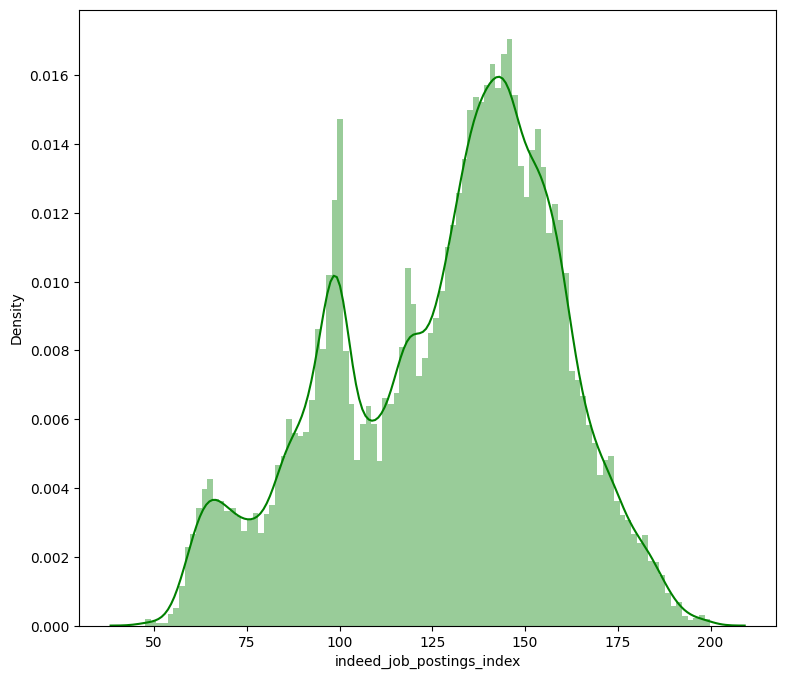

In [ ]:
# print(joinedDF['indeed_job_postings_index'].describe())
plt.figure(figsize=(9, 8));
firstList = sns.distplot(joinedDF['indeed_job_postings_index'], color='g', bins=100, hist_kws={'alpha': 0.4});
firstList;

<Figure size 2000x500 with 0 Axes>

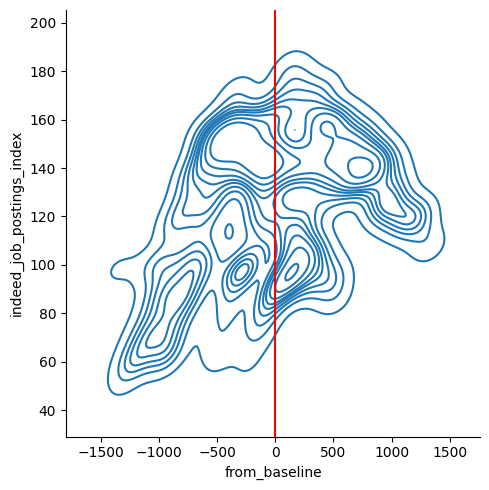

In [ ]:
plt.figure(figsize=(20,5))
sns.displot(data=joinedDF, x = "from_baseline", y = "indeed_job_postings_index",  kind="kde")
plt.axvline(x = 0, color = 'r')
plt.show()

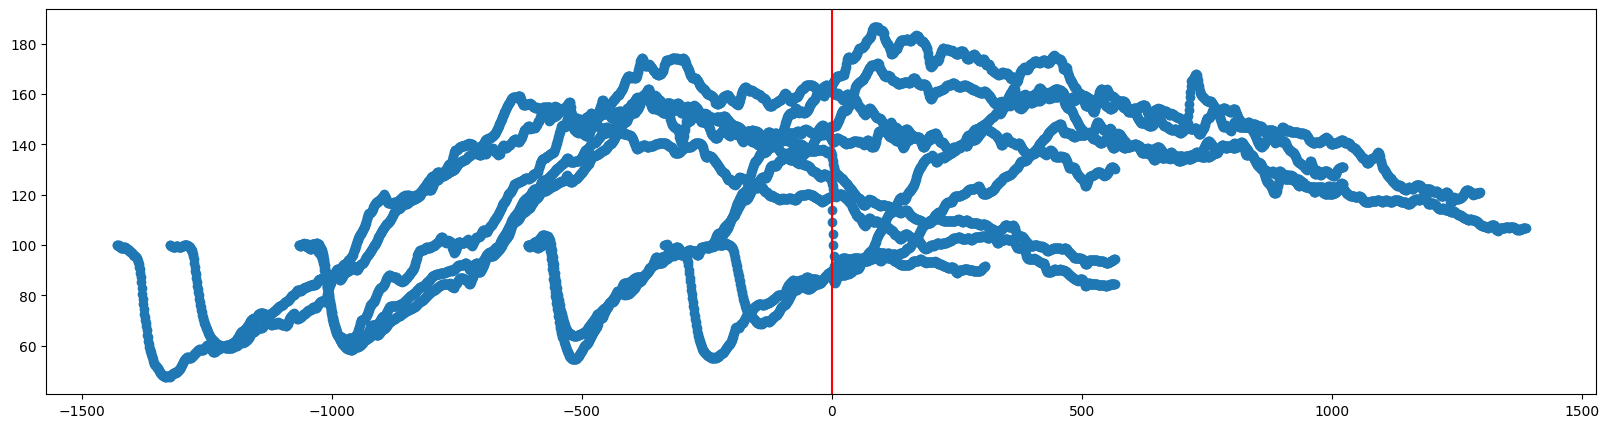

In [ ]:
x = joinedDF["from_baseline"]
y = joinedDF["indeed_job_postings_index"]
# Risize the figure (optional)
plt.figure(figsize=(20,5))

#Plot the x and y values on the graph
plt.scatter(x, y, )
plt.axvline(x = 0, color = 'r')
plt.show()


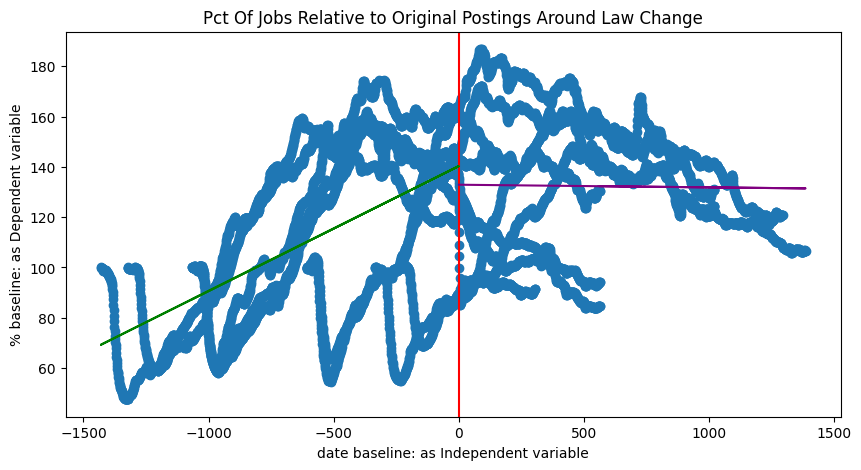

In [ ]:
df = joinedDF.dropna()
detail_graph(df,'indeed_job_postings_index','Pct Of Jobs Relative to Original Postings Around Law Change')

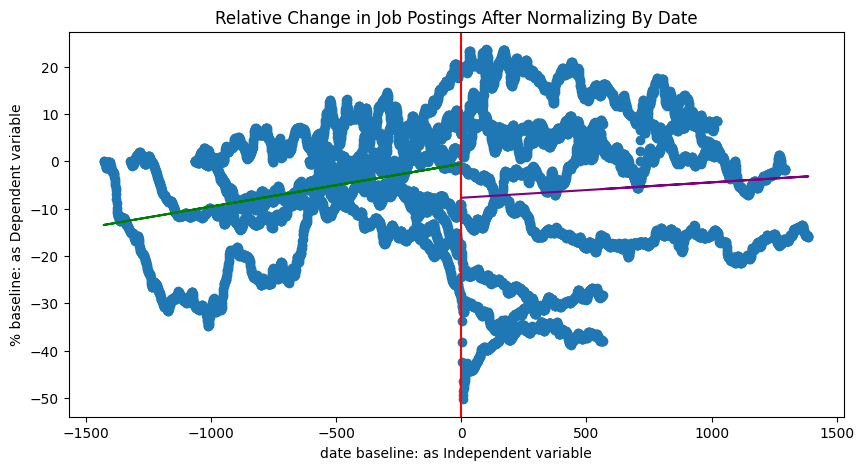

In [ ]:
detail_graph(ddf,'dPostings','Relative Change in Job Postings After Normalizing By Date')

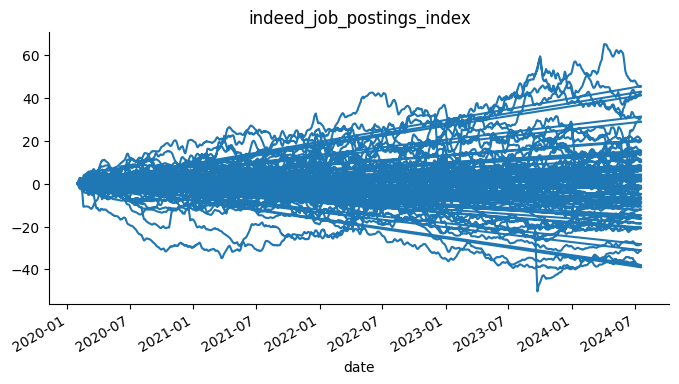

In [ ]:
from matplotlib import pyplot as plt
ddf['dPostings'].plot(kind='line', figsize=(8, 4), title='indeed_job_postings_index')
plt.gca().spines[['top', 'right']].set_visible(False)

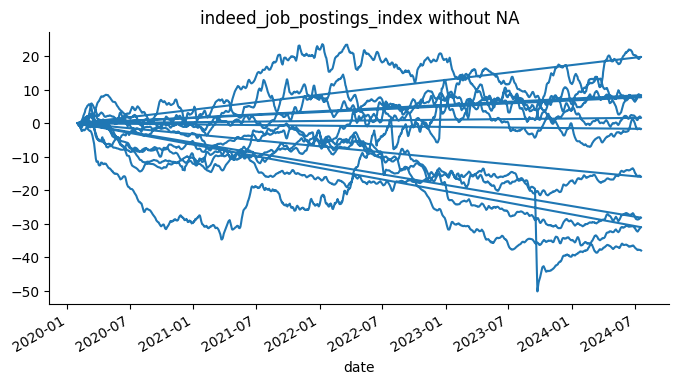

In [ ]:
# @title indeed_job_postings_index without states that dont have a date passed
ddf_na = ddf.dropna(subset=['date_passed'])

ddf_na['dPostings'].plot(kind='line', figsize=(8, 4), title='indeed_job_postings_index without NA')
plt.gca().spines[['top', 'right']].set_visible(False)



ValueError: cannot reindex on an axis with duplicate labels

<Figure size 1000x500 with 0 Axes>

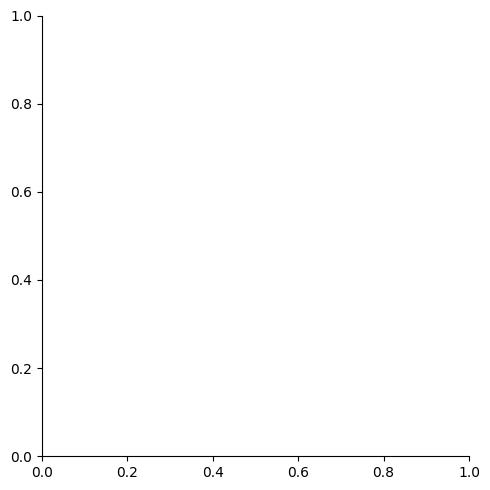

In [ ]:
import seaborn as sns
import pandas as pd
plt.figure(figsize=(10,5))
sns.displot(data=ddf, x = "from_baseline", y = "dPostings",  kind="kde")
plt.show()
#Add vertical line at 0

In [ ]:
# replacing the above graph with this
x = ddf["from_baseline"]
y = ddf["dPostings"]
# Risize the figure (optional)
plt.figure(figsize=(20,5))

#Plot the x and y values on the graph
plt.scatter(x, y, )
plt.axvline(x = 0, color = 'r')
plt.show()


In [ ]:
def scatter_with_gaussian_kde(ax, x, y):
    # https://stackoverflow.com/a/20107592/3015186
    # Answer by Joel Kington

    xy = np.vstack([x, y])
    z = gaussian_kde(xy)(xy)

    ax.scatter(x, y, c=z, s=100, edgecolor='')

In [ ]:
x = df[df['state'] == 'ny']["from_baseline"]
y = df[df['state'] == 'ny']["indeed_job_postings_index"]
# Risize the figure (optional)
plt.figure(figsize=(10,5))

#Plot the x and y values on the graph
plt.scatter(x, y, )
plt.axvline(x = 0, color = 'r')
plt.xlabel('Time To Law Passing')
plt.ylabel('Relative Proportion of Postings')
plt.title('New York: Pct Of Jobs Relative to Original Postings Around Law Change');
plt.show()

In [ ]:
from datetime import datetime


# editing the is_date_passed column

df = pd.read_csv('state_job_postings_us_072924.csv')

df["is_date_passed"]= pd.to_datetime(df['date_passed']).dt.date <= pd.to_datetime(df['date']).dt.date

pd.options.display.max_rows = 100
display(df)
pd.options.display.max_rows = 10

In [ ]:
# my code this week finishes here 04/27/24

In [ ]:
# prompt: create an example dataframe that includes a variable "pet type": dog, cat, bear, and bird.  Encode each of these types "one hot". Print this dataframe.

import pandas as pd

# Create a sample dataframe
df = pd.DataFrame({
    'pet type': ['dog', 'cat', 'bear', 'bird', 'dog', 'cat', 'bird']
})

# One-hot encode the 'pet type' column
df = pd.get_dummies(df, columns=['pet type'], prefix='pet type')

# Print the encoded dataframe
print(df)


In [ ]:
# prompt: Show me an example of a linear regression on ascombe's quartet (generate this data yourself). Show the full regression results table.

import numpy as np
import pandas as pd
import statsmodels.api as sm

# Generate Ascombe's quartet data
x = np.concatenate((np.random.normal(5, 2, 11), np.random.normal(15, 2, 11)))
y1 = x * 0.5 + 3 + np.random.normal(0, 4, 22)
y2 = x * 0.5 + 3 + np.random.normal(0, 4, 22)
y3 = x * 0.5 + 3 + np.random.normal(0, 4, 22)
y4 = x * 0.5 + 3 + np.random.normal(0, 4, 22)

# Create a DataFrame
data = {'x': x, 'y1': y1, 'y2': y2, 'y3': y3, 'y4': y4}
df = pd.DataFrame(data)

# Run a linear regression on each y variable
for y in ['y1', 'y2', 'y3', 'y4']:
    model = sm.OLS(df[y], sm.add_constant(df['x']))
    results = model.fit()
    print(results.summary())


In [ ]:
# prompt: Using the california_housing_test.csv data in sample_data folder, run a regression predicting home price using lot area. Show the results.summary() table as you did above.

import pandas as pd
import statsmodels.api as sm

# Read the data
df = pd.read_csv('sample_data/california_housing_test.csv')

# Define the dependent and independent variables
y = df['median_house_value']
X = df['total_rooms']

# Add a constant term to the independent variables
X = sm.add_constant(X)

# Create the model
model = sm.OLS(y, X)

# Fit the model
results = model.fit()

# Print the results summary
print(results.summary())


In [ ]:
# Resample the data and store the coefficients
coefs = []
for i in range(1000):
    df_resampled = df.sample(frac=1, replace=True)
    y = df_resampled['median_house_value']
    X = df_resampled['total_rooms']
    X = sm.add_constant(X)
    model = sm.OLS(y, X)
    results = model.fit()
    coefs.append(results.params['total_rooms'])

coefs = pd.DataFrame(coefs)

In [ ]:
# Display the coefficients
print(coefs.mean())
print(coefs.std())
print(coefs.min())

In [ ]:
E(y|x)